# Day 2: Exploratory Data Analysis & Physicochemical Feature Profiling
**Project:** Wine Quality Prediction (UCI Machine Learning Repository)
**Date:** October 6, 2026
**Tech Stack:** Python, pandas, numpy, seaborn, matplotlib, scikit-learn

## Objectives for Day 2
1. **Univariate Profiling:** Perform comprehensive statistical profiling (central tendency, dispersion, skewness, and kurtosis) across all 11 physicochemical features.
2. **Distribution Modeling:** Visualize univariate distributions via histograms and Kernel Density Estimates (KDE) to identify normality vs. heavy skew.
3. **Outlier Detection:** Quantify anomalous values across each attribute using Tukey's Interquartile Range (IQR) method and inspect spread via boxplots.
4. **Bivariate Target Analysis:** Investigate how individual chemical properties shift across sensory quality ratings (scale 3–8).
5. **Correlation & Multicollinearity:** Compute Pearson and Spearman rank correlation matrices, plot annotated heatmaps, and assess inter-feature collinearity.
6. **Domain Chemical Interpretation:** Connect data insights to enological principles (e.g., volatile acidity as acetic acid spoilage, alcohol and sulphates as preservatives and body enhancers).
7. **Actionable Roadmap for Day 3:** Establish clear requirements for feature engineering, skewness transforms, feature scaling, and class reformulation.

In [1]:
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure project root is in sys.path for local imports
project_root = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.data_loader import load_wine_data
from src.eda_profiling import (
    get_feature_columns,
    compute_univariate_stats,
    detect_outliers_iqr,
    compute_target_correlations,
    plot_univariate_distributions,
    plot_feature_boxplots,
    plot_features_vs_quality,
    plot_correlation_heatmap,
    plot_top_correlations_bar
)

# Visual style configuration
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

print('Setup complete. All modules imported successfully!')

Setup complete. All modules imported successfully!


## 1. Load Physicochemical Red Wine Dataset
We load the red wine dataset from `Data/winequality-red.csv`, containing 1,599 observations of 11 physicochemical measurements and 1 sensory quality rating.

In [2]:
df = load_wine_data('red', data_dir=project_root / 'Data')
features = get_feature_columns(df)
print(f'Dataset Shape: {df.shape[0]} samples, {df.shape[1]} columns')
print(f'Features ({len(features)}): {features}')
df.head()

Dataset Shape: 1599 samples, 12 columns
Features (11): ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


## 2. Univariate Statistical Profiling & Skewness Analysis
We compute a complete descriptive profile for all 11 physicochemical attributes, evaluating:
- **Central Tendency:** Mean vs. Median (50% percentile)
- **Dispersion:** Standard Deviation and Interquartile Range (IQR)
- **Shape:** Skewness (asymmetry) and Kurtosis (tail heaviness / peakedness)

In [3]:
stats_df = compute_univariate_stats(df, features)
stats_df

,Count,Mean,Std,Min,25%,Median (50%),75%,Max,IQR,Skewness,Kurtosis
Feature,,,,,,,,,,,
fixed acidity,1599,8.320,1.741,4.600,7.100,7.900,9.200,15.900,2.100,0.983,1.132
volatile acidity,1599,0.528,0.179,0.120,0.390,0.520,0.640,1.580,0.250,0.672,1.226
citric acid,1599,0.271,0.195,0.000,0.090,0.260,0.420,1.000,0.330,0.318,-0.789
residual sugar,1599,2.539,1.410,0.900,1.900,2.200,2.600,15.500,0.700,4.541,28.618
chlorides,1599,0.087,0.047,0.012,0.070,0.079,0.090,0.611,0.020,5.680,41.716
free sulfur dioxide,1599,15.875,10.460,1.000,7.000,14.000,21.000,72.000,14.000,1.251,2.024
total sulfur dioxide,1599,46.468,32.895,6.000,22.000,38.000,62.000,289.000,40.000,1.516,3.810
density,1599,0.997,0.002,0.990,0.996,0.997,0.998,1.004,0.002,0.071,0.934
pH,1599,3.311,0.154,2.740,3.210,3.310,3.400,4.010,0.190,0.194,0.807


### Key Univariate Findings:
1. **Heavily Skewed Features:**
   - `chlorides` (skewness = **+5.680**, kurtosis = **41.714**): High positive skew with extreme outliers up to 0.611 g/dm$^3$ compared to a median of 0.079.
   - `residual sugar` (skewness = **+4.541**, kurtosis = **28.618**): Extreme right skew where most dry red wines have 1.9–2.6 g/dm$^3$, but occasional sweet variants reach up to 15.5 g/dm$^3$.
   - `sulphates` (skewness = **+2.429**, kurtosis = **11.720**): Noticeable right tail with potassium sulphate concentrations extending to 2.0 g/dm$^3$.
   - `free sulfur dioxide` (skewness = **+1.251**) and `total sulfur dioxide` (skewness = **+1.516**): Positively skewed due to preservative concentrations in specific wine batches.

2. **Approximately Normal Features:**
   - `density` (skewness = **+0.071**): Virtually symmetric and centered tightly around 0.9967 g/cm$^3$.
   - `pH` (skewness = **+0.194**): Near-perfect Gaussian distribution centered around 3.31.

3. **Moderately Skewed Features:**
   - `fixed acidity` (skewness = **+0.983**), `alcohol` (skewness = **+0.861**), and `volatile acidity` (skewness = **+0.672**).

## 3. Visualizing Physicochemical Feature Distributions
Histograms with overlaid Kernel Density Estimates (KDE) and markers for mean (red dashed line) and median (green dotted line) clarify distribution shapes and asymmetry.

Distribution plot saved to: C:\Users\Iba Zaidi\Desktop\Wine Quality Prediction\reports\figures\day2_univariate_distributions.png


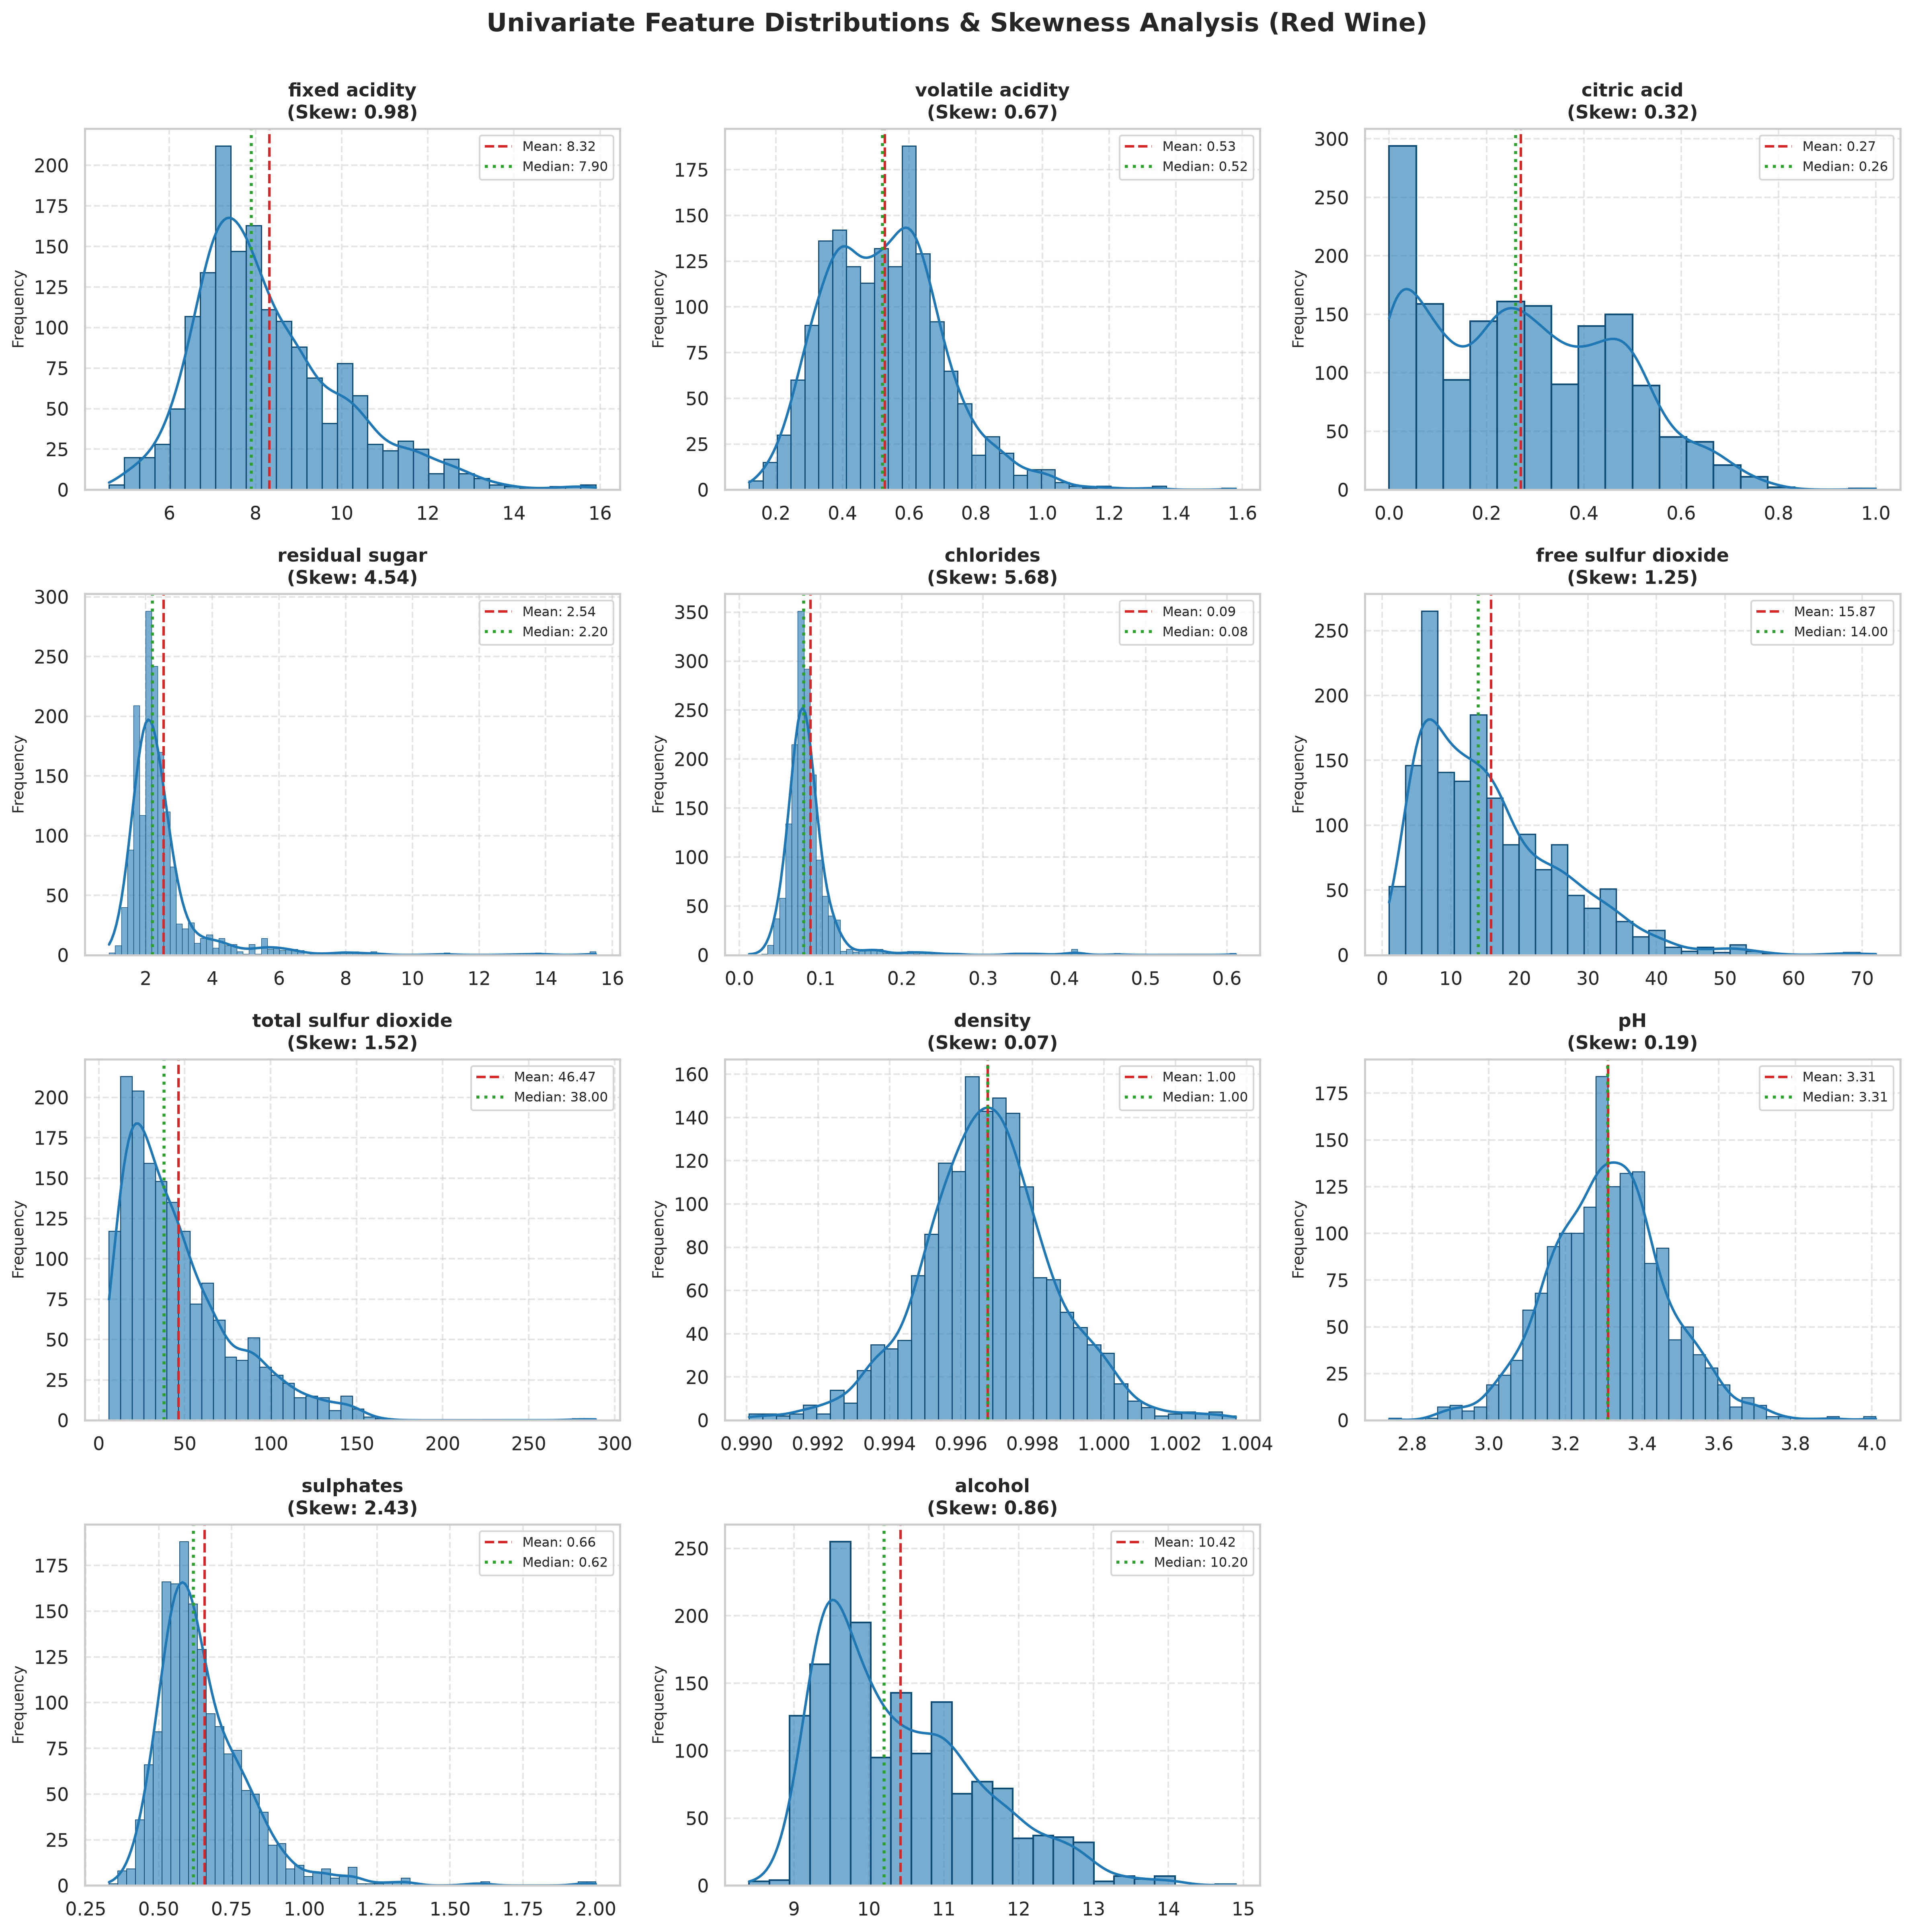

In [4]:
fig_dir = project_root / 'reports' / 'figures'
fig_dir.mkdir(parents=True, exist_ok=True)
dist_path = fig_dir / 'day2_univariate_distributions.png'

plot_univariate_distributions(df, features, save_path=str(dist_path))

# Display inline
from IPython.display import Image
Image(filename=str(dist_path))

## 4. Quantitative Outlier Detection & Boxplot Analysis
Using **Tukey's Fences** with threshold factor $k=1.5$:
$$\text{Lower Fence} = Q_1 - 1.5 \times \text{IQR}, \quad \text{Upper Fence} = Q_3 + 1.5 \times \text{IQR}$$
Observations falling outside these boundaries are classified as statistical outliers.

In [5]:
outlier_df = detect_outliers_iqr(df, features)
outlier_df

,Q1 (25%),Q3 (75%),IQR,Lower Fence,Upper Fence,Low Outliers,High Outliers,Total Outliers,Outlier Pct (%)
Feature,,,,,,,,,
fixed acidity,7.100,9.200,2.100,3.950,12.350,0,49,49,3.06
volatile acidity,0.390,0.640,0.250,0.015,1.015,0,19,19,1.19
citric acid,0.090,0.420,0.330,-0.405,0.915,0,1,1,0.06
residual sugar,1.900,2.600,0.700,0.850,3.650,0,155,155,9.69
chlorides,0.070,0.090,0.020,0.040,0.120,9,103,112,7.00
free sulfur dioxide,7.000,21.000,14.000,-14.000,42.000,0,30,30,1.88
total sulfur dioxide,22.000,62.000,40.000,-38.000,122.000,0,55,55,3.44
density,0.996,0.998,0.002,0.992,1.001,21,24,45,2.81
pH,3.210,3.400,0.190,2.925,3.685,14,21,35,2.19


### 4.1 Feature Boxplots (Spread & Outlier Concentration)
Let's visualize the interquartile ranges and outlier points highlighted in red.

Boxplot saved to: C:\Users\Iba Zaidi\Desktop\Wine Quality Prediction\reports\figures\day2_feature_boxplots.png


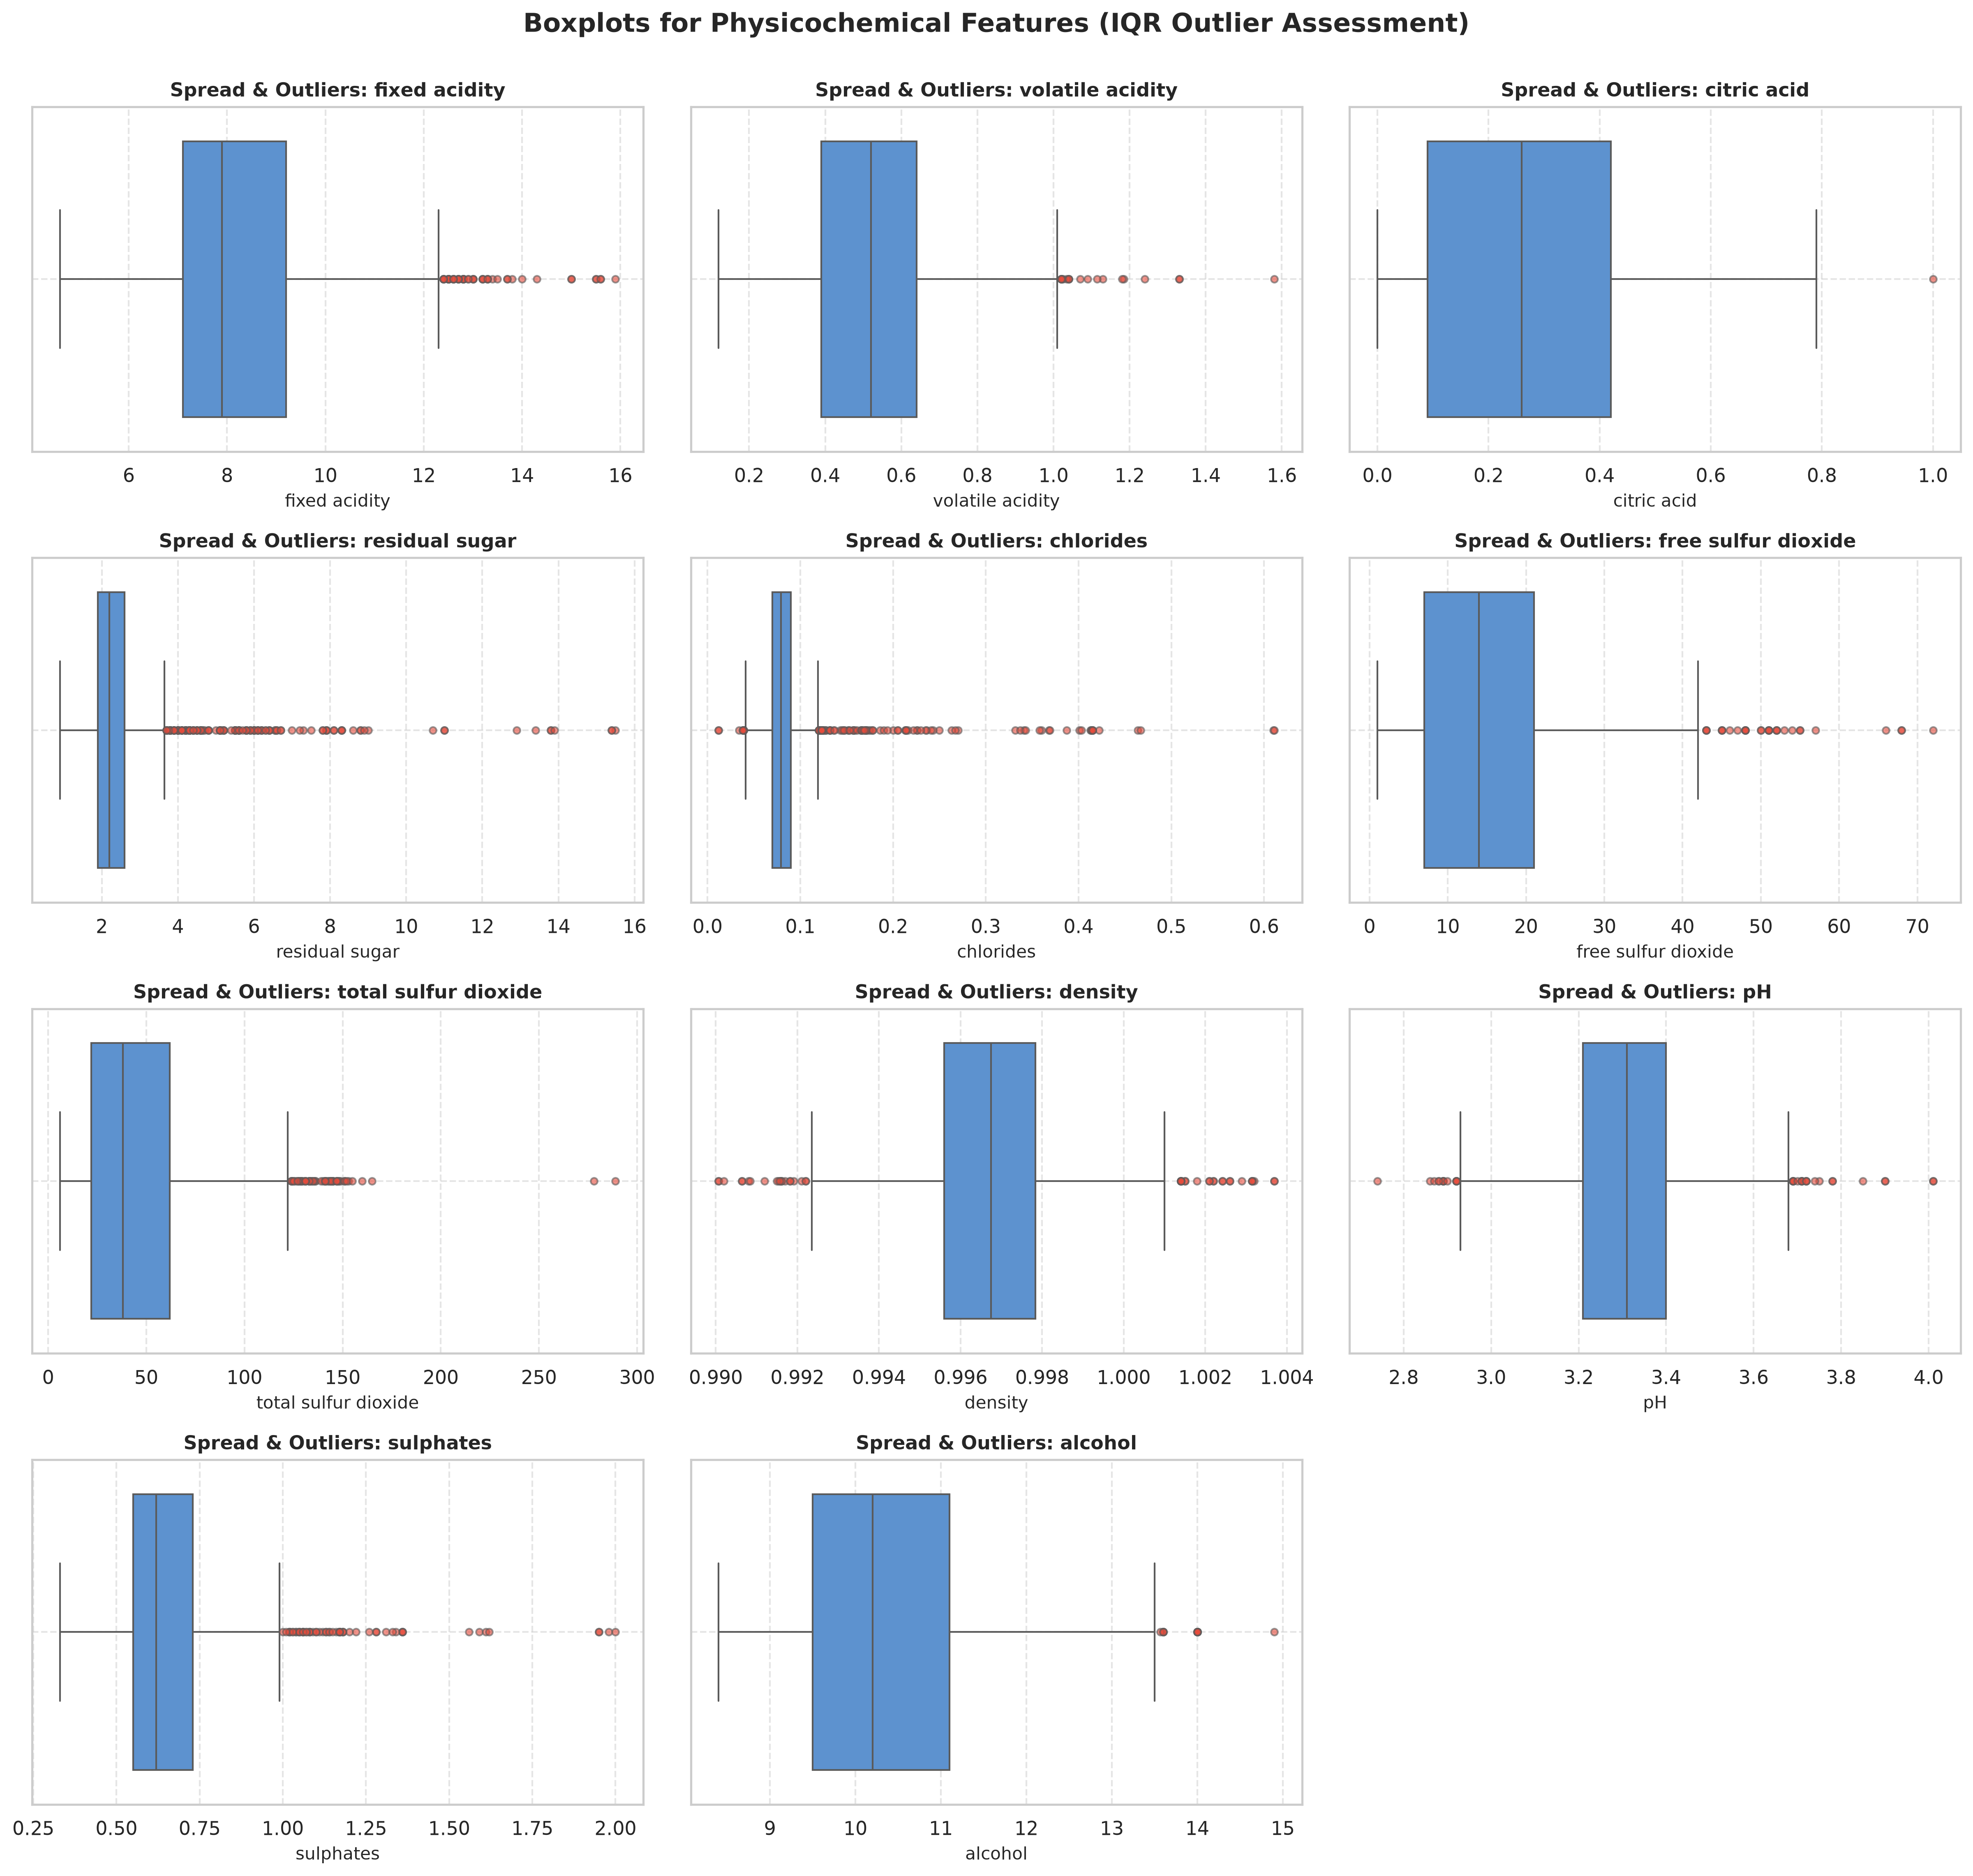

In [6]:
boxplot_path = fig_dir / 'day2_feature_boxplots.png'
plot_feature_boxplots(df, features, save_path=str(boxplot_path))
Image(filename=str(boxplot_path))

### Outlier Evaluation & Treatment Strategy:
1. **Prevalence:**
   - `residual sugar`: 155 samples (**9.69%**) exceed the upper fence (3.65 g/dm$^3$). These reflect semi-sweet or sweet red wine styles, not erroneous records.
   - `chlorides`: 112 samples (**7.00%**) exceed the upper fence (0.119 g/dm$^3$), reflecting higher mineral salt content.
   - `total sulfur dioxide`: 55 samples (**3.44%**) exceed 122 mg/dm$^3$, with two extreme wines exceeding 275 mg/dm$^3$.
2. **Domain Validity:** Chemical features are measured through precise laboratory assays; these values represent genuine enological variability rather than data entry errors.
3. **Modeling Strategy for Day 3:**
   - Tree-based ensemble models (Random Forest, Gradient Boosting) are naturally invariant to monotonic transformations and robust to univariate outliers.
   - For distance-sensitive algorithms (Support Vector Classifier, Logistic Regression, SGD), `RobustScaler` (scaling by median and IQR) or log/power transforms will be applied to prevent extreme values from dominating decision hyperplanes.

## 5. Bivariate Analysis: Physicochemical Features Across Quality Scores
How do chemical attributes change across sensory quality ratings (scale 3 to 8)?
We inspect boxplots of each feature partitioned by target quality score.

Bivariate plot saved to: C:\Users\Iba Zaidi\Desktop\Wine Quality Prediction\reports\figures\day2_features_vs_quality.png


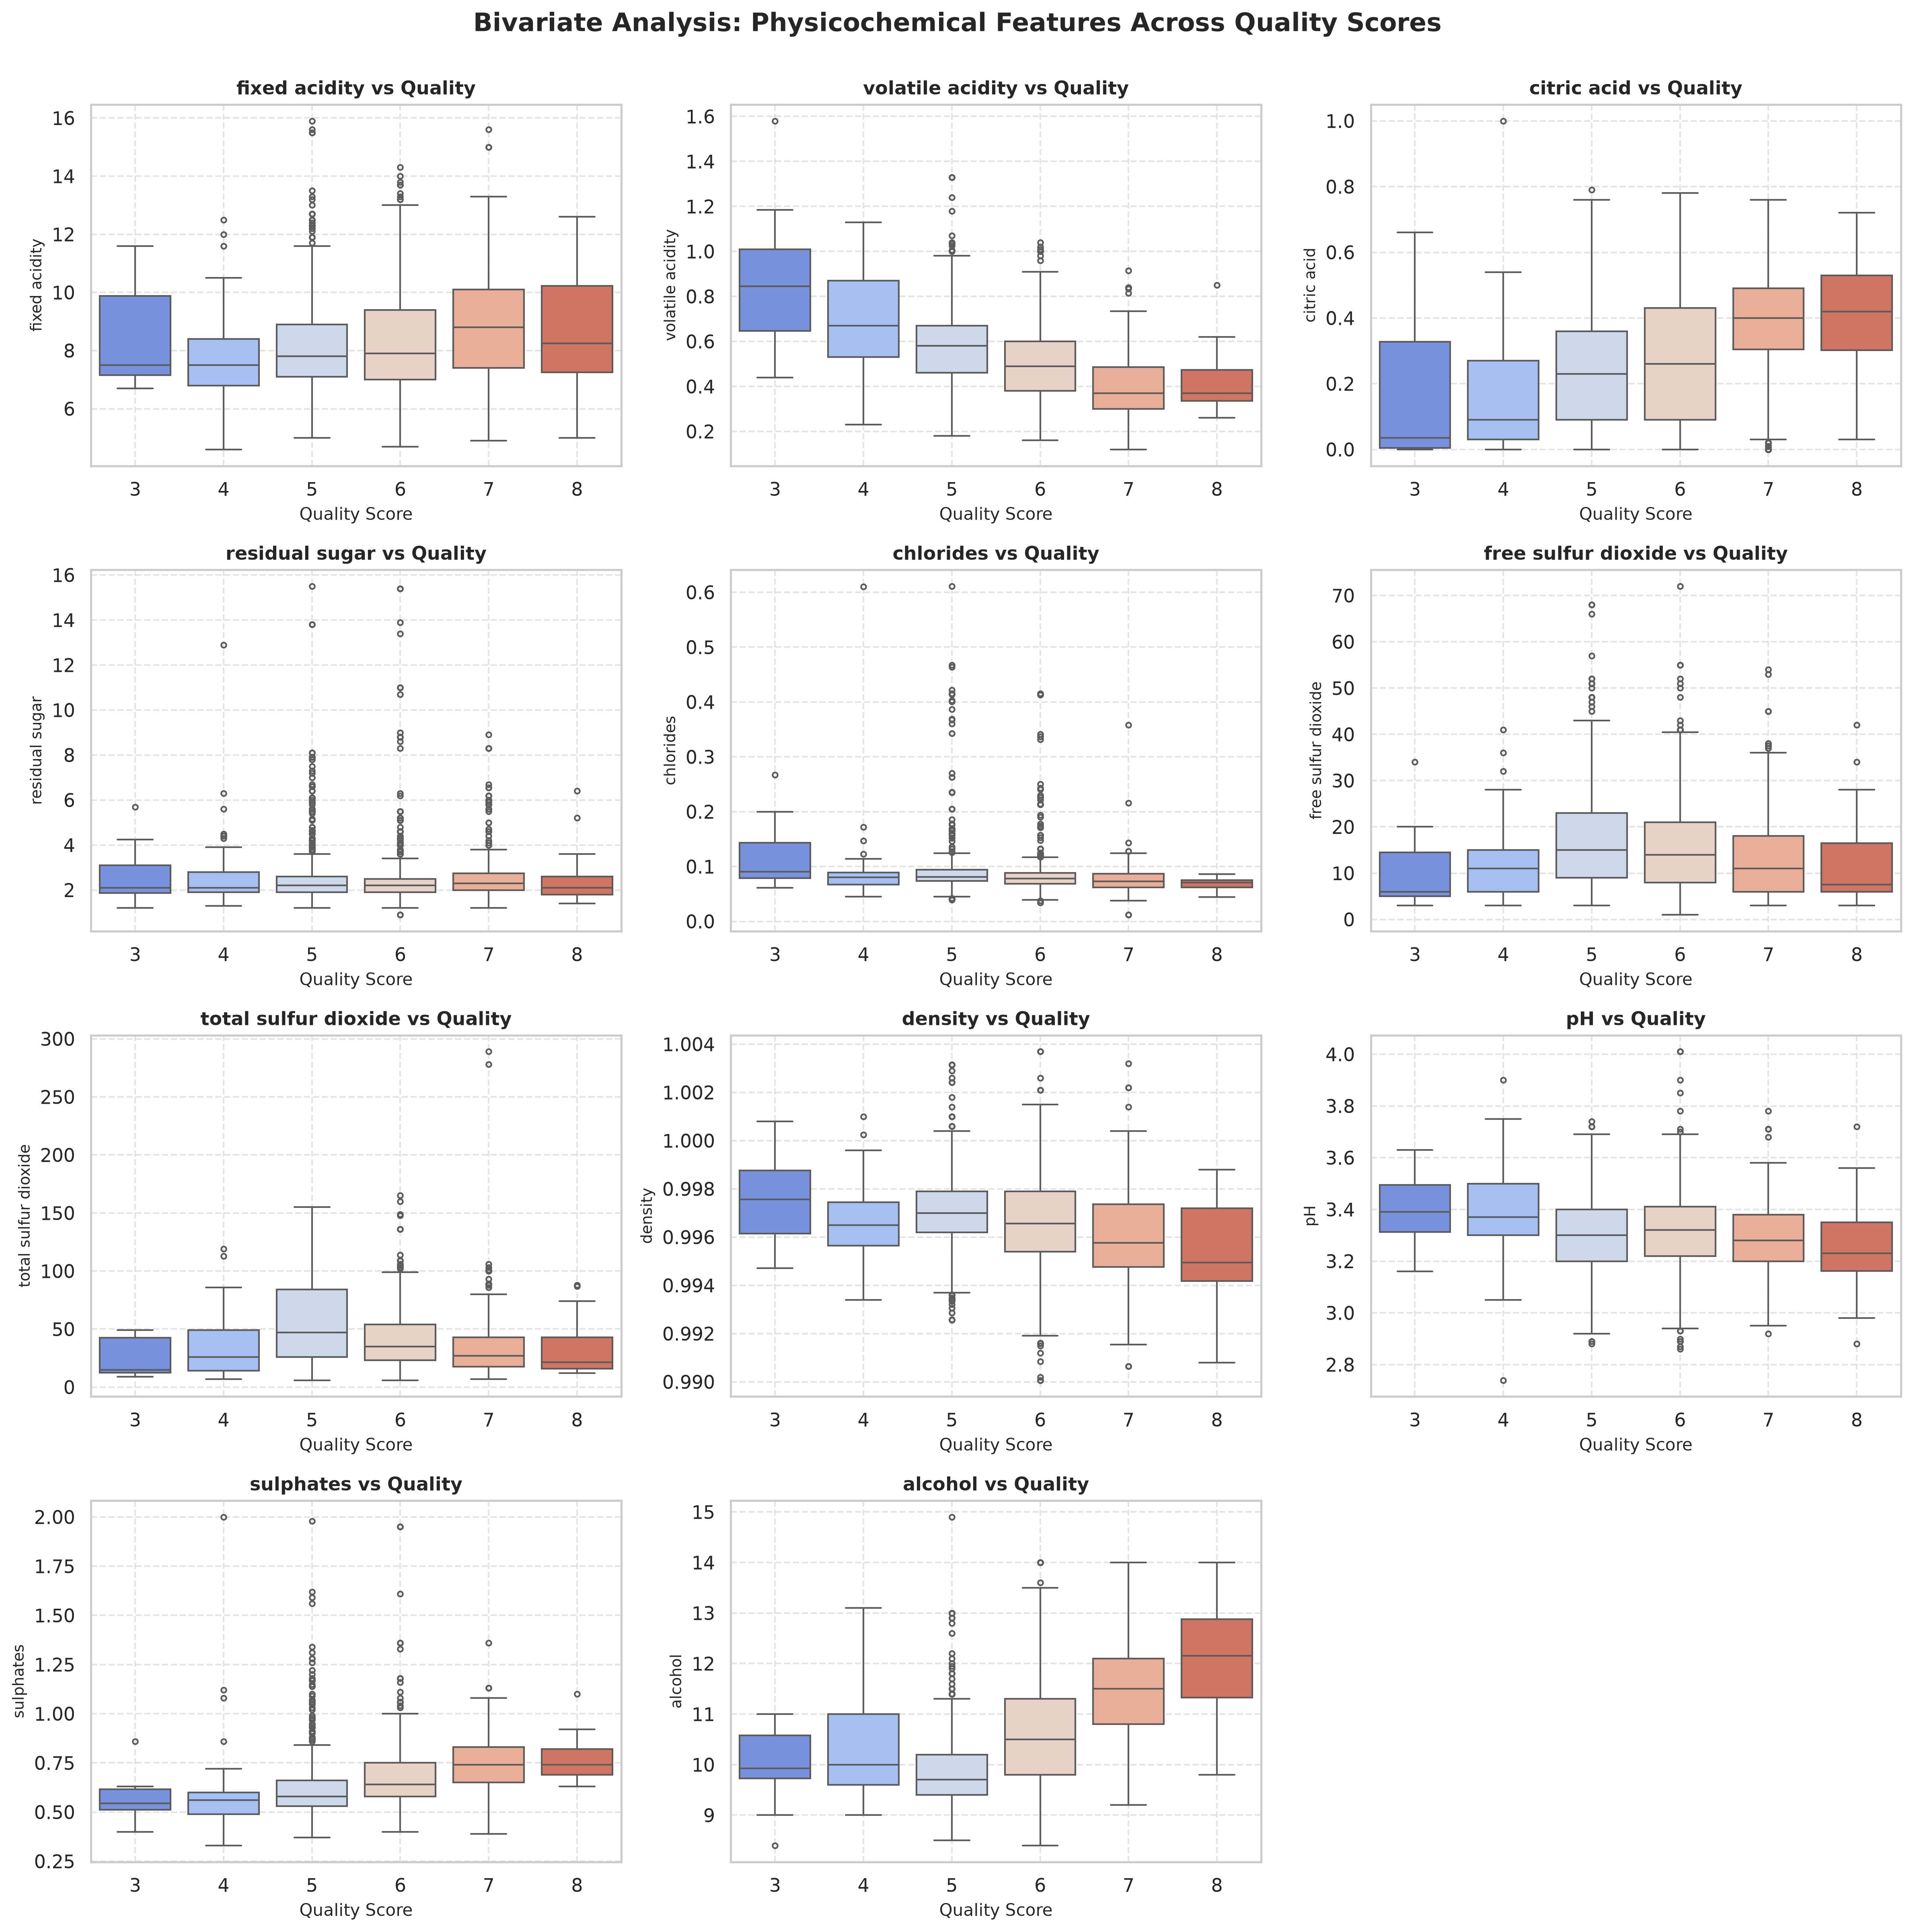

In [7]:
biv_path = fig_dir / 'day2_features_vs_quality.png'
plot_features_vs_quality(df, features, target_col='quality', save_path=str(biv_path))
Image(filename=str(biv_path))

### Key Bivariate Insights:
1. **Alcohol (Strong Positive Trend):**
   - Quality 3 & 4 wines have median alcohol levels around **9.9%–10.0%**.
   - Quality 7 & 8 wines exhibit significantly higher median alcohol around **11.5%–12.1%**.
   - Higher alcohol confers body, fullness, and perceived sweetness that wine tasters consistently reward.

2. **Volatile Acidity (Strong Negative Trend):**
   - Quality 3 wines exhibit high median volatile acidity (~**0.84 g/dm$^3$**).
   - Quality 8 wines drop to median volatile acidity of ~**0.37 g/dm$^3$**.
   - Volatile acidity corresponds to acetic acid (vinegar). Elevated concentrations directly degrade sensory aroma and taste.

3. **Citric Acid (Positive Trend):**
   - Quality 3 wines contain near-zero citric acid (median **0.035 g/dm$^3$**).
   - Quality 7 & 8 wines average **0.40–0.42 g/dm$^3$**, providing freshness and crispness.

4. **Sulphates (Positive Trend):**
   - Potassium sulphate increases steadily from median ~**0.54** in score 3 to ~**0.74** in score 8. Sulphates serve as antimicrobial and antioxidant agents preserving wine integrity.

## 6. Correlation Matrix & Multicollinearity Analysis
We examine linear (Pearson) and monotonic (Spearman) relationships between predictors and target quality, as well as inter-feature correlations.

In [8]:
target_corr = compute_target_correlations(df, target_col='quality')
print('Feature Correlations with Sensory Quality:')
target_corr

Feature Correlations with Sensory Quality:


,Feature,Pearson Correlation,Spearman Correlation,Abs Pearson,Direction
0,alcohol,0.4762,0.4785,0.4762,Positive
1,volatile acidity,-0.3906,-0.3806,0.3906,Negative
2,sulphates,0.2514,0.3771,0.2514,Positive
3,citric acid,0.2264,0.2135,0.2264,Positive
4,total sulfur dioxide,-0.1851,-0.1967,0.1851,Negative
5,density,-0.1749,-0.1771,0.1749,Negative
6,chlorides,-0.1289,-0.1899,0.1289,Negative
7,fixed acidity,0.1241,0.1141,0.1241,Positive
8,pH,-0.0577,-0.0437,0.0577,Negative
9,free sulfur dioxide,-0.0507,-0.0569,0.0507,Negative


findfont: Failed to find font weight medium for DejaVu Sans, now using 400.


Bar correlation plot saved to: C:\Users\Iba Zaidi\Desktop\Wine Quality Prediction\reports\figures\day2_top_correlations.png


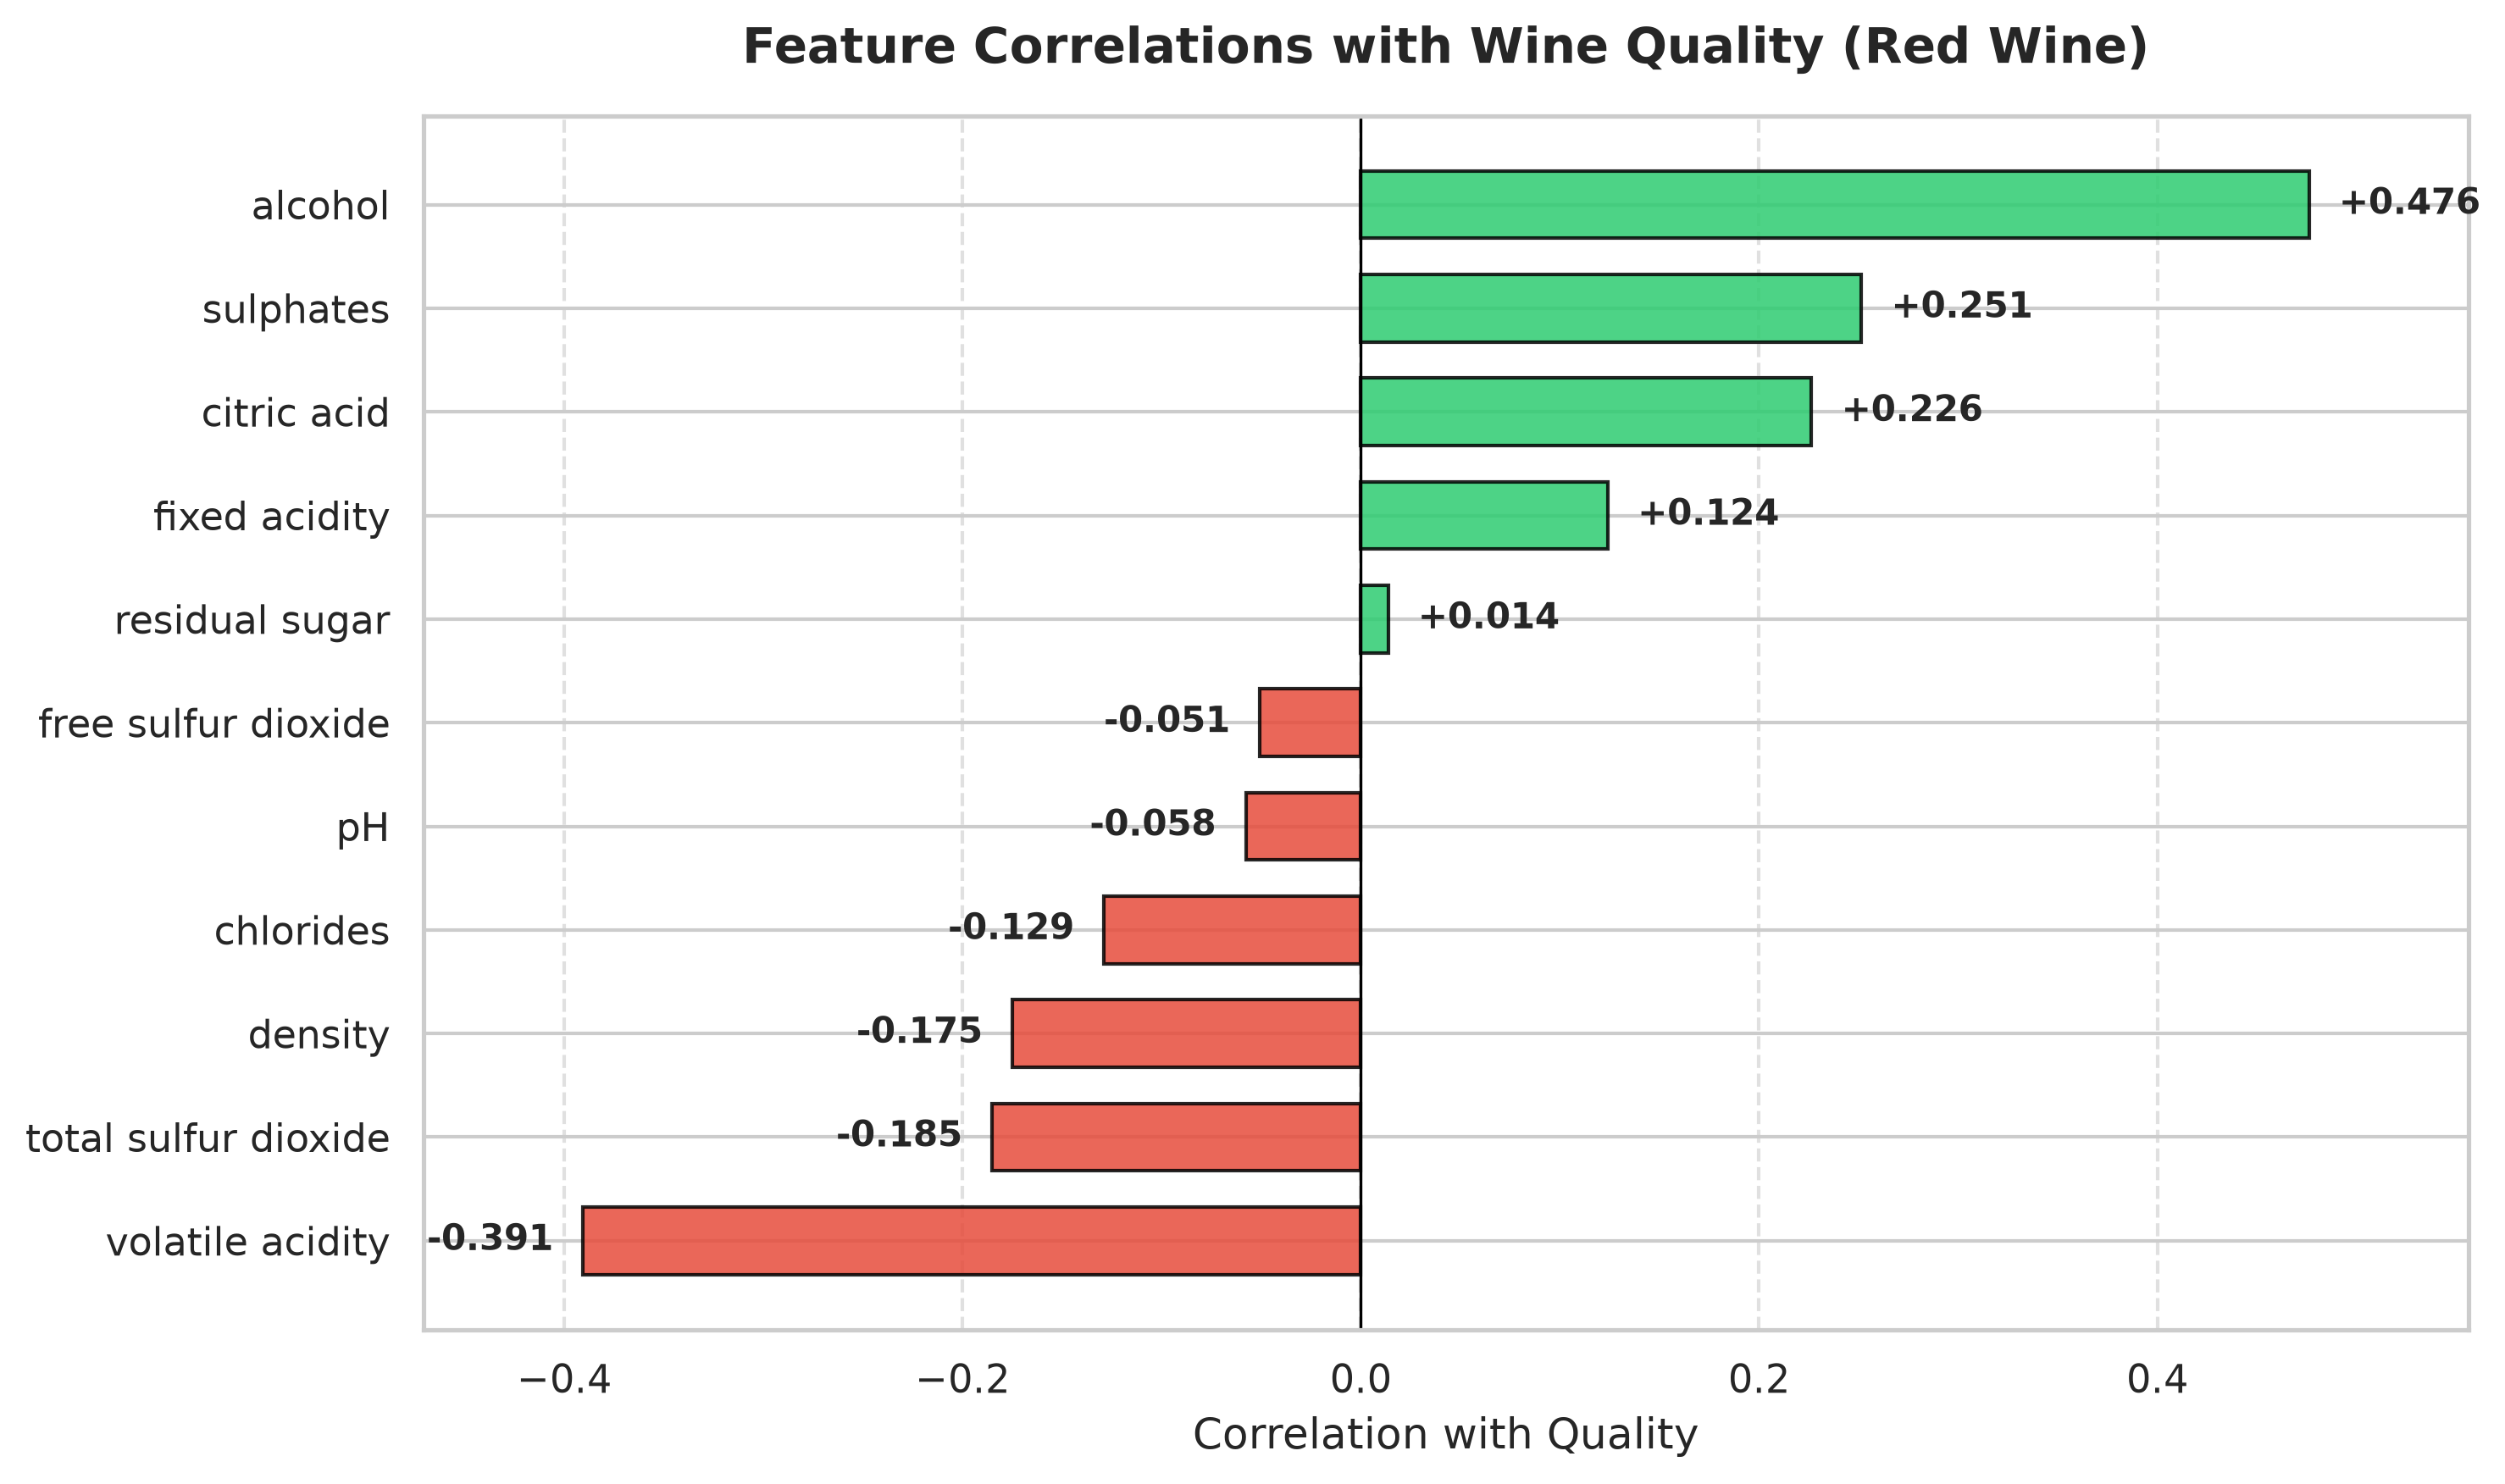

In [9]:
bar_path = fig_dir / 'day2_top_correlations.png'
plot_top_correlations_bar(df, target_col='quality', save_path=str(bar_path))
Image(filename=str(bar_path))

### 6.1 Inter-Feature Correlation Heatmap
Evaluating multicollinearity among the 11 physicochemical predictors.

Heatmap saved to: C:\Users\Iba Zaidi\Desktop\Wine Quality Prediction\reports\figures\day2_correlation_heatmap.png


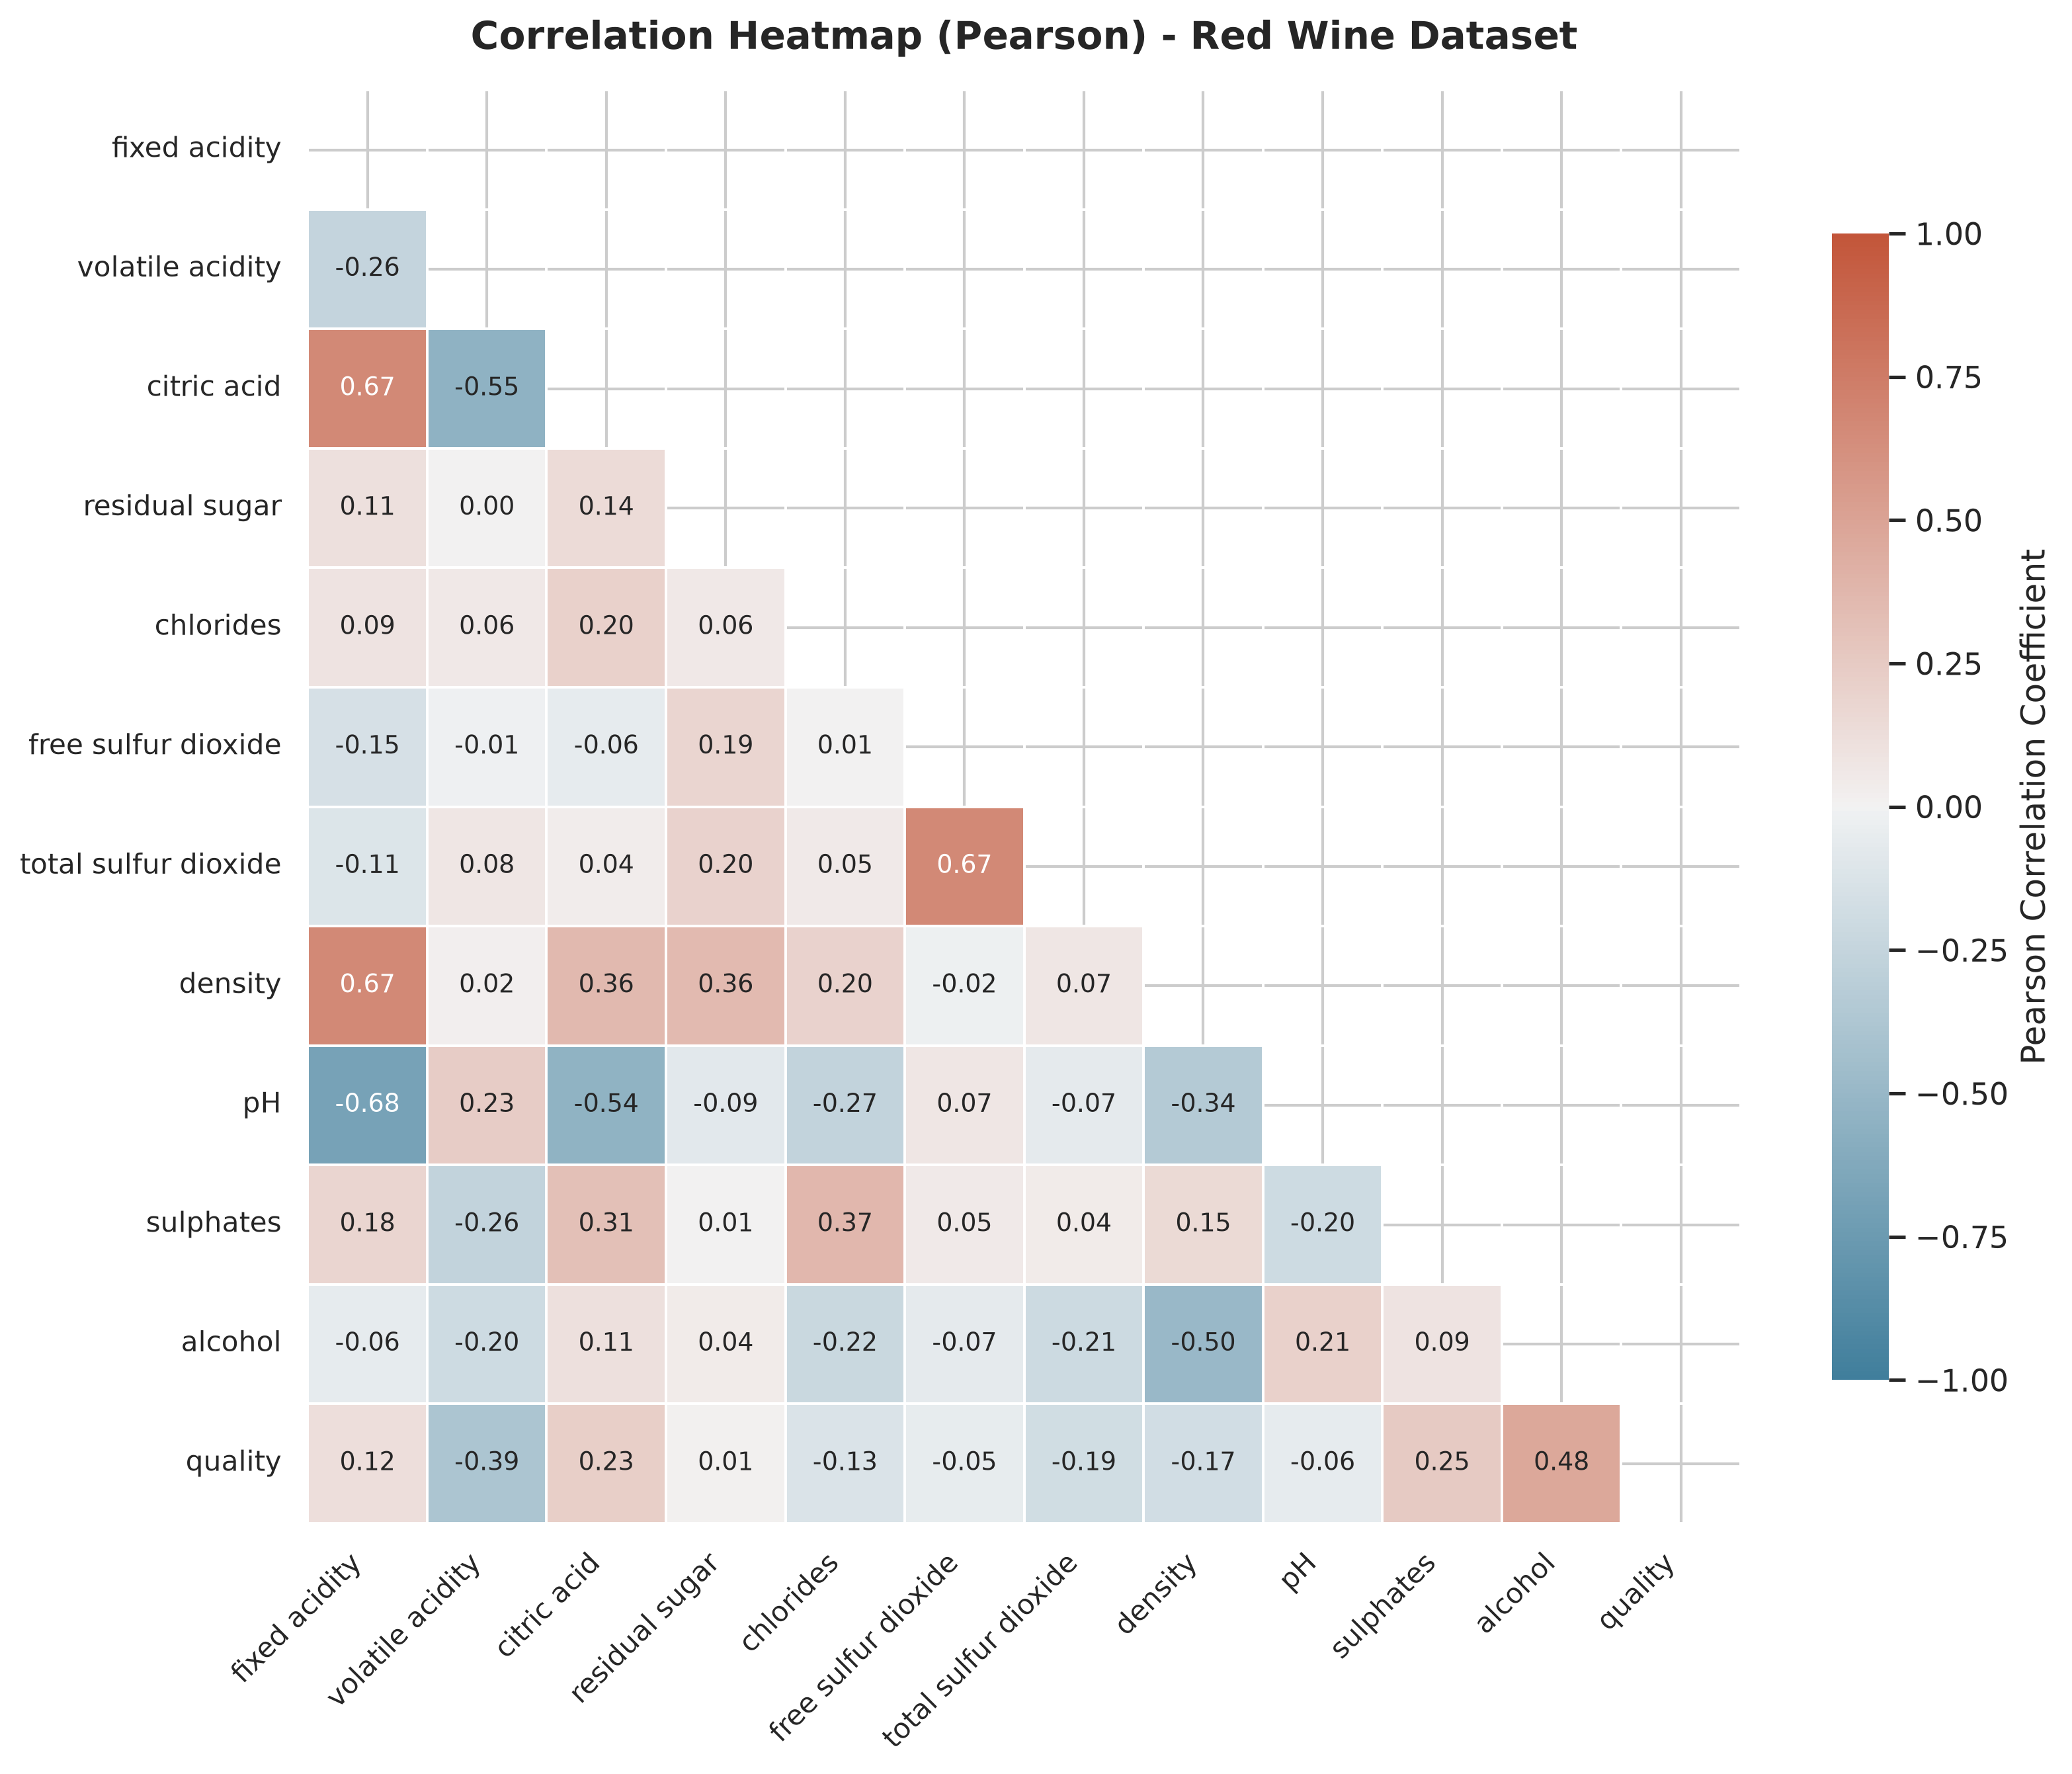

In [10]:
heatmap_path = fig_dir / 'day2_correlation_heatmap.png'
plot_correlation_heatmap(df, save_path=str(heatmap_path), method='pearson')
Image(filename=str(heatmap_path))

### Multicollinearity Analysis & Chemical Rationale:

| Feature Pair | Pearson $r$ | Enological / Physical Explanation |
| :--- | :---: | :--- |
| `fixed acidity` vs. `pH` | **-0.68** | Direct chemical relationship: higher acidic proton concentration lowers pH ($-\log[H^+]$). |
| `fixed acidity` vs. `citric acid` | **+0.67** | Citric acid is a primary organic acid constituent of fixed acidity. |
| `fixed acidity` vs. `density` | **+0.67** | Concentrated tartaric acid increases the overall mass density of aqueous wine solutions. |
| `free SO2` vs. `total SO2` | **+0.67** | Free sulfur dioxide ($SO_2$) is an equilibrium component of total sulfur dioxide. |
| `citric acid` vs. `volatile acidity` | **-0.55** | Clean fermentations with high citric acid typically prevent acetic acid bacterial spoilage. |
| `density` vs. `alcohol` | **-0.50** | Ethanol has lower specific gravity ($\approx 0.789$ g/cm$^3$) than water, decreasing wine density. |

> **Collinearity Impact:** High correlations between `fixed acidity`, `citric acid`, `density`, and `pH` can cause variance inflation in unregularized linear models. Regularization ($L_1$/$L_2$ penalties) or tree-based feature selection will be essential in modeling.

## 7. Day 2 Synthesis & Actionable Plan for Day 3

### Key Takeaways from Day 2:
1. **Core Predictors of Wine Quality:**
   - **Alcohol Content** ($r = +0.48$): The strongest single positive predictor of quality.
   - **Volatile Acidity** ($r = -0.39$): The strongest negative predictor; acetic acid spoilage strongly detracts from quality.
   - **Sulphates** ($r = +0.25$) & **Citric Acid** ($r = +0.23$): Statistically significant positive contributors.
2. **Negligible Direct Predictors:**
   - `residual sugar` ($r = +0.01$) and `free sulfur dioxide` ($r = -0.05$) show minimal linear correlation with quality, indicating they are baseline sanitary requirements rather than discriminators of excellence.
3. **Data Preprocessing Needs:**
   - Right-skewed features (`chlorides`, `residual sugar`, `sulphates`) require log1p or power transforms for linear models.
   - Feature scaling via `RobustScaler` is recommended due to valid extreme values in chemical assays.

### Actionable Roadmap for Day 3 (Feature Engineering & Baseline Modeling):
- **Target Transformation:** Reframe the imbalanced multi-class problem into actionable binary classification (Good Wine: $\text{quality} \ge 7$ vs. Normal/Poor Wine: $\text{quality} < 7$).
- **Feature Engineering:** Create domain-driven interaction features (e.g., total acid ratio, free-to-total $SO_2$ ratio, sugar-alcohol balance).
- **Pipeline Construction:** Build standardized scikit-learn pipelines with `RobustScaler` and `StandardScaler`.
- **Baseline Classification Models:** Train and benchmark Random Forest, Support Vector Classifier (SVC), and Stochastic Gradient Descent (SGD) with stratified cross-validation.